# 02 · Cleaning and exploring the property.co.zw data

**Research question.** Which features explain the asking prices of houses for sale in Zimbabwe, and how accurately can a model predict them?

This notebook is step 2 of the project. It takes the listings collected by `property_scraper.py` (step 1) and produces a clean modelling set for the models in step 3.

| | |
|---|---|
| **Input** | `zim_property_data/listings.csv` (the scraper output; a copy is kept in `data/listings_raw.csv`) |
| **Outputs** | `data/houses_clean.csv` (modelling set), `data/all_listings_deduped.csv` (all property types), `tables/*.csv`, `figures/*.png` |
| **How to run** | Open the notebook and choose *Run all*. It looks for the project folder (the one containing `zim_property_data/`) by itself; if it cannot find it, set `PROJECT_ROOT` in the setup cell. Every cleaning rule is in the configuration cell, so you can change a threshold and re-run. |

**What this notebook does:** (1) loads and describes the raw data, (2) removes duplicates, (3) puts prices in one currency, (4) tidies locations, (5) narrows to houses, (6) removes impossible values, (7) deals with missing values, (8) builds features, and (9) explores the cleaned data with tables and plots.

## 0 · Setup and cleaning rules

In [1]:
import os, re, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# ---- find the project folder (the one that contains zim_property_data/) and work from there
PROJECT_ROOT = None      # if the notebook cannot find it by itself, put the folder here, e.g. "C:/house_project"
def find_project_root():
    if PROJECT_ROOT:
        return PROJECT_ROOT
    here = os.path.abspath(os.getcwd())
    folders = [here]
    for _ in range(3):
        folders.append(os.path.dirname(folders[-1]))
    for folder in folders:
        if (os.path.exists(os.path.join(folder, "zim_property_data", "listings.csv"))
                or os.path.exists(os.path.join(folder, "data", "listings_raw.csv"))):
            return folder
    raise FileNotFoundError(f"Could not find zim_property_data/listings.csv from {here}. "
                            "Set PROJECT_ROOT in this cell to your project folder, e.g. PROJECT_ROOT = 'C:/house_project'.")
os.chdir(find_project_root())
print("Working folder:", os.getcwd())

# ---- paths (relative to the project folder)
RAW_DIR = "zim_property_data"                      # where the scraper saved its output
DATA, FIG, TAB = "data", "figures", "tables"       # where this notebook writes its results
for folder in (DATA, FIG, TAB):
    os.makedirs(folder, exist_ok=True)
RAW_CSV = os.path.join(RAW_DIR, "listings.csv")
if not os.path.exists(RAW_CSV):                    # e.g. when running from the submitted repository
    RAW_CSV = os.path.join(DATA, "listings_raw.csv")

# ---- cleaning rules (change here and re-run)
MODEL_TYPES = ["houses"]                 # only listings the site classes as houses are modelled (townhouses, flats, land are left out)
PRICE_MIN, PRICE_MAX = 5_000, 5_000_000  # USD. Outside this range a price is treated as an error or not a house
BEDROOMS_RANGE = (1, 12)                 # rows outside are dropped (hotels / blocks of flats listed as houses)
BATHROOMS_MAX, GARAGES_MAX = 12, 10      # larger values are typos -> set to missing
FLOOR_RANGE = (25, 4_000)                # m2; outside -> set to missing
LAND_RANGE = (50, 100_000)               # m2 (10 hectares); outside -> set to missing
LAT_RANGE, LON_RANGE = (-22.5, -15.5), (25.0, 33.2)   # Zimbabwe's bounding box; a map pin outside it is an error -> set to missing
MIN_SUBURB_COUNT = 10                    # rarer suburbs are grouped as "Other" in suburb_grouped
AMENITY_MIN_SHARE = 0.03                 # amenities present in >= 3% of houses get a 0/1 column
ZWG_PER_USD = None                       # all prices are USD; if ZWG ever appears, set a rate or those rows are dropped

cleaning_log = []
def step(name, before, after, note=""):
    cleaning_log.append({"step": name, "rows_before": before, "rows_after": after, "rows_removed": before - after, "note": note})
    print(f"{name:52s} {before:>6} -> {after:>6}   {note}")

def save_show(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG, name), bbox_inches="tight"); plt.show()

def boxes(ax, data, labels, horizontal=False):
    """Boxplot that works on old and new matplotlib versions."""
    try:
        ax.boxplot(data, orientation="horizontal" if horizontal else "vertical", showfliers=False)
    except TypeError:
        ax.boxplot(data, vert=not horizontal, showfliers=False)
    (ax.set_yticklabels if horizontal else ax.set_xticklabels)(labels)

Working folder: C:\house_project


## 1 · Load the raw data

Each row is one listing scraped from property.co.zw, with the asking price, location, size and room counts, amenities, the agent's description and photo links. `date_collected` records when each listing was scraped. A copy of the raw file is saved in `data/` for the submission.

In [2]:
raw = pd.read_csv(RAW_CSV, low_memory=False)
for c in ("date_posted", "date_collected"):
    raw[c] = pd.to_datetime(raw[c], errors="coerce")
raw.to_csv(os.path.join(DATA, "listings_raw.csv"), index=False, encoding="utf-8")

print(f"{len(raw):,} listings, {raw.shape[1]} columns. Collected on: {raw['date_collected'].min().date()} to {raw['date_collected'].max().date()}")
display(raw[["listing_id", "property_type_url", "title", "price_raw", "suburb", "bedrooms", "bathrooms", "floor_size_m2", "land_size_m2"]].head(5))

6,035 listings, 52 columns. Collected on: 2026-11-22 to 2026-11-25


,listing_id,property_type_url,title,price_raw,suburb,bedrooms,bathrooms,floor_size_m2,land_size_m2
0,pgp259484,townhouses,Modern 4 Bed Villas In Northwood,"$320,000",Northwood,4.0,2.0,209.0,500.0
1,pbox259991,houses,Waterfalls Uplands Property On 1 Acre For Sale...,"$230,000",Waterfalls,3.0,2.0,287.8,4282.0
2,kwrz259146,houses,"Thatched Duplex Retreat on 5,300 m² in Greenda...","$510,000",Greendale North,3.0,2.0,450.0,5300.0
3,pgp205420,houses,Perfect family home,"$230,000",Goodhope,5.0,3.0,100.0,2000.0
4,cac193006,townhouses,Introducing the Modern Cluster Units in Parkto...,"$110,000",Waterfalls,4.0,3.0,300.0,500.0


### What was collected

The task asks for houses mainly, plus flats, apartments and land so that cleaning can be demonstrated on every type. The table shows how many listings of each type were collected, before any cleaning.

In [3]:
raw_by_type = (raw.groupby("property_type_url")
                  .agg(listings=("listing_id", "size"), median_price_usd=("price_value", "median"), price_missing_pct=("price_value", lambda s: round(s.isna().mean() * 100, 1)))
                  .sort_values("listings", ascending=False))
raw_by_type.to_csv(os.path.join(TAB, "table_raw_listings_by_type.csv"))
display(raw_by_type)

,listings,median_price_usd,price_missing_pct
property_type_url,,,
houses,2329,185000.0,0.6
residential-land-stands,1467,50000.0,4.5
commercial-land,349,320000.0,0.9
flats-apartments,343,150000.0,0.6
warehouses,314,780000.0,1.0
townhouses,310,240000.0,0.3
agricultural-land-farms,246,160000.0,1.2
land,157,65000.0,0.0
garden-flats,141,160000.0,0.0


## 2 · Remove duplicates

Two kinds of duplicate are possible. **Repeated listing IDs** come from scraping the same page twice. **Near-duplicates** are the same property posted more than once, which agents often do. I treat two listings as the same property when the first 200 characters of the description, the price and the suburb all match, and keep the newest posting. I did *not* use bedrooms and sizes alone, because identical units in one cluster or complex are genuinely different listings.

In [4]:
df = raw.copy()
step("Loaded", len(df), len(df))

n = len(df)
df = df.drop_duplicates("listing_id")
step("Drop repeated listing_id", n, len(df))

n = len(df)
df["_desc"] = df["description"].fillna("").str.lower().str.replace(r"\W+", " ", regex=True).str.strip().str[:200]
df = df.sort_values("date_posted", ascending=False)
is_dup = (df["_desc"].str.len() > 40) & df["price_value"].notna() & df.duplicated(["_desc", "price_value", "suburb"], keep="first")
df = df[~is_dup].drop(columns="_desc")
step("Drop near-duplicate listings", n, len(df), "same description + price + suburb; newest kept")

Loaded                                                 6035 ->   6035   
Drop repeated listing_id                               6035 ->   6035   
Drop near-duplicate listings                           6035 ->   5979   same description + price + suburb; newest kept


## 3 · Prices in one currency

The site shows prices in US dollars. This step checks that no listing is priced in another currency, and would convert Zimbabwe Gold (ZWG) prices if there were any.

In [5]:
n = len(df)
zwg = df["currency"].eq("ZWG")
if zwg.any():
    if ZWG_PER_USD:
        df.loc[zwg, "price_value"] = df.loc[zwg, "price_value"] / ZWG_PER_USD
        df.loc[zwg, "currency"] = "USD"
    else:
        df = df[~zwg]
df["price_usd"] = df["price_value"]
step("Prices in one currency (USD)", n, len(df), f"{int(zwg.sum())} ZWG rows; currencies present: {df['currency'].dropna().unique().tolist()}")
print("Listings with no price (shown as 'P.O.A.' on the site):", int(df["price_usd"].isna().sum()))

Prices in one currency (USD)                           5979 ->   5979   0 ZWG rows; currencies present: ['USD']
Listings with no price (shown as 'P.O.A.' on the site): 99


## 4 · Tidy the location

The scraped location is "Suburb, Region, City" for Harare (for example *Highlands, Harare North, Harare*), but outside Harare the last part is a province (*Murambi, Mutare, Manicaland*). I create a simple `city_clean` (Harare, Bulawayo, Chitungwiza, Other) and keep the second part as `area_clean`.

In [6]:
loc = df["location_raw"].fillna("")
df["city_clean"] = np.select(
    [loc.eq(""), loc.str.contains("harare", case=False), loc.str.contains("bulawayo", case=False), loc.str.contains("chitungwiza", case=False)],
    ["Unknown", "Harare", "Bulawayo", "Chitungwiza"], default="Other")
df["area_clean"] = df["area"].fillna("Unknown")

df.to_csv(os.path.join(DATA, "all_listings_deduped.csv"), index=False, encoding="utf-8")   # every property type, de-duplicated
display(df["city_clean"].value_counts().to_frame("listings").T)

city_clean,Harare,Other,Bulawayo,Chitungwiza,Unknown
listings,3810,1415,577,117,60


## 5 · Narrow to houses

The research question is about houses, so the modelling set keeps only listings the site classifies as `houses`. Townhouses, flats, land and commercial listings stay in `data/all_listings_deduped.csv` (so that cleaning is shown on every type) but are not modelled. Before fixing anything, here is what the raw house data looks like.

In [7]:
n = len(df)
h = df[df["property_type_url"].isin(MODEL_TYPES)].copy()
step("Keep houses only (modelling set)", n, len(h), "other types stay in all_listings_deduped.csv")

check_cols = ["price_usd", "bedrooms", "bathrooms", "garages", "floor_size_m2", "land_size_m2", "latitude", "longitude", "city_clean", "amenities"]
miss_before = h[check_cols].isna().mean().mul(100).round(1)
print("\nMissing values (%) before cleaning:")
display(miss_before.to_frame("missing_%").T)
print("Extreme values before cleaning (note the impossible maxima):")
display(h[["price_usd", "bedrooms", "bathrooms", "garages", "floor_size_m2", "land_size_m2"]]
        .describe(percentiles=[.01, .5, .99]).loc[["min", "1%", "50%", "99%", "max"]].round(0))

Keep houses only (modelling set)                       5979 ->   2307   other types stay in all_listings_deduped.csv

Missing values (%) before cleaning:


,price_usd,bedrooms,bathrooms,garages,floor_size_m2,land_size_m2,latitude,longitude,city_clean,amenities
missing_%,0.6,0.1,11.7,46.0,11.9,1.3,48.1,48.1,0.0,20.2


Extreme values before cleaning (note the impossible maxima):


,price_usd,bedrooms,bathrooms,garages,floor_size_m2,land_size_m2
min,110.0,1.0,1.0,1.0,0.0,0.0
1%,23000.0,2.0,1.0,1.0,1.0,1.0
50%,185000.0,4.0,2.0,1.0,300.0,1472.0
99%,1800000.0,8.0,8.0,4.0,8315.0,24270.0
max,7500000.0,42.0,13.0,200.0,2023430.0,105210000.0


## 6 · Remove rows we cannot use

* **No price.** The price is the variable we predict, so listings marked "P.O.A." (price on application) are dropped.
* **Implausible price.** Prices below \$5,000 are typos, deposits or monthly rents. At the top, anything above \$5 million is development land listed under "houses".
* **Extreme bedroom counts.** Listings with more than 12 bedrooms are lodges or blocks, not ordinary houses.

In [8]:
n = len(h); h = h[h["price_usd"].notna()]
step("Drop listings with no price (P.O.A.)", n, len(h), "target variable missing")

n = len(h)
dropped = h[~h["price_usd"].between(PRICE_MIN, PRICE_MAX)][["listing_id", "title", "price_raw", "bedrooms", "land_size_m2"]]
h = h[h["price_usd"].between(PRICE_MIN, PRICE_MAX)]
step("Drop implausible prices", n, len(h), f"outside ${PRICE_MIN:,}-${PRICE_MAX:,}")
display(dropped)

n = len(h); h = h[h["bedrooms"].between(*BEDROOMS_RANGE)]
step("Drop missing / extreme bedroom counts", n, len(h), f"outside {BEDROOMS_RANGE[0]}-{BEDROOMS_RANGE[1]} bedrooms")

Drop listings with no price (P.O.A.)                   2307 ->   2294   target variable missing
Drop implausible prices                                2294 ->   2290   outside $5,000-$5,000,000


,listing_id,title,price_raw,bedrooms,land_size_m2
2328,glre256630,Elegant Double-Storey 5-Bed in Opp Borrowdale ...,"$4,000",5.0,600.0
1647,ft256364,Sale,$300,4.0,4600.0
1932,ding255297,House in Mabvazuwa Estate,$110,4.0,400.0
413,pgp223079,Premium 10.6-Acre Development Land (Sole Mandate),"$7,500,000",9.0,43000.0


Drop missing / extreme bedroom counts                  2290 ->   2283   outside 1-12 bedrooms


## 7 · Impossible values become missing

Some sizes and counts are clearly errors (a floor size of 0 m², 2 million m², 150 bathrooms). These are probably typos or unit mistakes (for example a land size typed in the floor-size box). Map coordinates are checked too: a pin outside Zimbabwe is a mistake (one house in the data is pinned in the Arctic, at latitude 85, longitude −180). The house is still useful, so I set only the impossible value to missing instead of dropping the whole row, and deal with it in the next step.

In [9]:
fixed = {}
def blank(col, bad, label):
    k = int((bad & h[col].notna()).sum()); h.loc[bad, col] = np.nan; fixed[label] = k

blank("bathrooms", (h["bathrooms"] < 1) | (h["bathrooms"] > BATHROOMS_MAX), "bathrooms outside 1-%d" % BATHROOMS_MAX)
blank("garages", (h["garages"] < 0) | (h["garages"] > GARAGES_MAX), "garages above %d" % GARAGES_MAX)
blank("floor_size_m2", (h["floor_size_m2"] < FLOOR_RANGE[0]) | (h["floor_size_m2"] > FLOOR_RANGE[1]), "floor size outside %d-%d m2" % FLOOR_RANGE)
blank("land_size_m2", (h["land_size_m2"] < LAND_RANGE[0]) | (h["land_size_m2"] > LAND_RANGE[1]), "land size outside %d-%d m2" % LAND_RANGE)
bad_pin = h["latitude"].notna() & ~(h["latitude"].between(*LAT_RANGE) & h["longitude"].between(*LON_RANGE))
h.loc[bad_pin, ["latitude", "longitude"]] = np.nan
fixed["map pin outside Zimbabwe (houses)"] = int(bad_pin.sum())

for label, k in fixed.items():
    cleaning_log.append({"step": "Impossible value -> missing", "rows_before": "", "rows_after": "", "rows_removed": 0, "note": f"{k} values: {label}"})
display(pd.Series(fixed, name="values set to missing").to_frame())

,values set to missing
bathrooms outside 1-12,1
garages above 10,2
floor size outside 25-4000 m2,157
land size outside 50-100000 m2,47
map pin outside Zimbabwe (houses),1


## 8 · Deal with missing values

| Variable | Missing because | Treatment |
|---|---|---|
| `garages` | The count is only recorded when the advert mentions a garage | Fill with 0 and keep a flag `garages_not_stated` |
| `bathrooms` | Not stated, or removed above | Median for houses with the same number of bedrooms |
| `floor_size_m2` | Not stated, or removed above | Median for the same city and number of bedrooms |
| `land_size_m2` | Not stated, or removed above | Median for the same area |
| `latitude`, `longitude` | The listing has no map pin | Average for the same suburb (then area, then city) |

Each filled variable has a 0/1 column ending in `_imputed`, so a model can tell real values from estimates. **Caveat:** these medians are computed on the whole dataset. For the final models, repeat the fill using the training rows only, so test-set information does not leak into the training data.

In [10]:
def fill_by_group(col, groups):
    s = h[col]
    for g in groups:
        s = s.fillna(h.groupby(g)[col].transform("median"))
    return s.fillna(h[col].median())

h["garages_not_stated"] = h["garages"].isna().astype(int)
h["garages"] = h["garages"].fillna(0)
rules = {"bathrooms": [["bedrooms"]],
         "floor_size_m2": [["city_clean", "bedrooms"], ["bedrooms"]],
         "land_size_m2": [["area_clean"], ["city_clean"]],
         "latitude": [["suburb", "city_clean"], ["area_clean"], ["city_clean"]],
         "longitude": [["suburb", "city_clean"], ["area_clean"], ["city_clean"]]}
for col, groups in rules.items():
    h[col + "_imputed"] = h[col].isna().astype(int)
    h[col] = fill_by_group(col, groups)

summary = pd.DataFrame({"rows filled": {"garages (as 0)": int(h["garages_not_stated"].sum()), "bathrooms": int(h["bathrooms_imputed"].sum()),
                                        "floor_size_m2": int(h["floor_size_m2_imputed"].sum()), "land_size_m2": int(h["land_size_m2_imputed"].sum()),
                                        "latitude/longitude": int(h["latitude_imputed"].sum())}})
summary["% of houses"] = (summary["rows filled"] / len(h) * 100).round(1)
cleaning_log.append({"step": "Fill missing values", "rows_before": len(h), "rows_after": len(h), "rows_removed": 0,
                     "note": "garages->0; bathrooms by bedrooms; floor by city+bedrooms; land by area; lat/lon by suburb; *_imputed flags kept"})
display(summary)

,rows filled,% of houses
garages (as 0),1053,46.1
bathrooms,265,11.6
floor_size_m2,429,18.8
land_size_m2,77,3.4
latitude/longitude,1101,48.2


## 9 · Build features

* `log_price` (the natural log of the price): prices are very right-skewed, so models usually work better on the log scale.
* `suburb_grouped` (rare suburbs combined as "Other"), `desc_words` (length of the description) and `listing_age_days` (days between posting and collection).
* **Amenity columns.** The `amenities` text (for example "Borehole|Electric Gate|Garden") becomes one 0/1 column per amenity present in at least 3% of houses, plus `n_amenities`.
* `price_outlier_flag`: marks prices more than 1.5 IQRs outside their city's quartiles on the log scale. These are kept, only flagged, because expensive houses are real.
* `n_photos` (how many photos were downloaded for the house) is added if the downloaded photo index is available.

In [11]:
h["log_price"] = np.log(h["price_usd"])
counts = h["suburb"].value_counts()
h["suburb_grouped"] = np.where(h["suburb"].map(counts).fillna(0) >= MIN_SUBURB_COUNT, h["suburb"], "Other")
h["desc_words"] = h["description"].fillna("").str.split().str.len()
h["listing_age_days"] = (h["date_collected"] - h["date_posted"]).dt.days

am = h["amenities"].fillna("").str.split("|").apply(lambda lst: [x.strip() for x in lst if x.strip()])
h["amenities_listed"] = am.map(len).gt(0).astype(int)
h["n_amenities"] = am.map(len)
share = am.explode().value_counts() / len(h)
amen_cols = []
for a in share[share >= AMENITY_MIN_SHARE].index:
    col = "amen_" + re.sub(r"[^a-z0-9]+", "_", a.lower()).strip("_")
    h[col] = am.map(lambda lst, a=a: int(a in lst)); amen_cols.append(col)

q = h.groupby("city_clean")["log_price"].quantile([.25, .75]).unstack()
iqr = q[0.75] - q[0.25]
lo, hi = h["city_clean"].map(q[0.25] - 1.5 * iqr), h["city_clean"].map(q[0.75] + 1.5 * iqr)
h["price_outlier_flag"] = ((h["log_price"] < lo) | (h["log_price"] > hi)).astype(int)

index_path = os.path.join(RAW_DIR, "image_index.csv")
photo_cols = []
if os.path.exists(index_path):
    ix = pd.read_csv(index_path)
    h["n_photos"] = h["listing_id"].map(ix.groupby("listing_id").size()).fillna(0).astype(int)
    photo_cols = ["n_photos"]

print(f"{len(amen_cols)} amenity columns created. Most common:")
display((share.head(8) * 100).round(1).to_frame("% of houses").T)

36 amenity columns created. Most common:


amenities,Main En Suite,Walled,Fitted Kitchen,Borehole,Verandah,Tiled,Good ZESA,Garden
% of houses,51.9,51.8,48.4,47.3,46.3,46.3,44.9,42.6


## 10 · Save the cleaned data and the cleaning log

In [12]:
keep = (["listing_id", "listing_url", "title", "property_type_url", "date_posted", "date_collected", "listing_age_days",
         "price_usd", "log_price", "price_outlier_flag", "city_clean", "area_clean", "suburb", "suburb_grouped", "latitude", "longitude",
         "bedrooms", "bathrooms", "garages", "floor_size_m2", "land_size_m2", "agent_name", "n_amenities", "amenities_listed",
         "garages_not_stated", "bathrooms_imputed", "floor_size_m2_imputed", "land_size_m2_imputed", "latitude_imputed"]
        + amen_cols + [c for c in h.columns if c.startswith("flag_")] + ["desc_words"] + photo_cols + ["amenities", "description"])
houses = h[keep].sort_values("listing_id").reset_index(drop=True)
houses.to_csv(os.path.join(DATA, "houses_clean.csv"), index=False, encoding="utf-8")
step("FINAL modelling set -> data/houses_clean.csv", len(houses), len(houses), f"{houses.shape[1]} columns")

log_table = pd.DataFrame(cleaning_log)
log_table.to_csv(os.path.join(TAB, "table_cleaning_log.csv"), index=False)
display(log_table)

FINAL modelling set -> data/houses_clean.csv           2283 ->   2283   94 columns


,step,rows_before,rows_after,rows_removed,note
0,Loaded,6035,6035,0,
1,Drop repeated listing_id,6035,6035,0,
2,Drop near-duplicate listings,6035,5979,56,same description + price + suburb; newest kept
3,Prices in one currency (USD),5979,5979,0,0 ZWG rows; currencies present: ['USD']
4,Keep houses only (modelling set),5979,2307,3672,other types stay in all_listings_deduped.csv
5,Drop listings with no price (P.O.A.),2307,2294,13,target variable missing
6,Drop implausible prices,2294,2290,4,"outside $5,000-$5,000,000"
7,Drop missing / extreme bedroom counts,2290,2283,7,outside 1-12 bedrooms
8,Impossible value -> missing,,,0,1 values: bathrooms outside 1-12
9,Impossible value -> missing,,,0,2 values: garages above 10


### Rows removed at each step

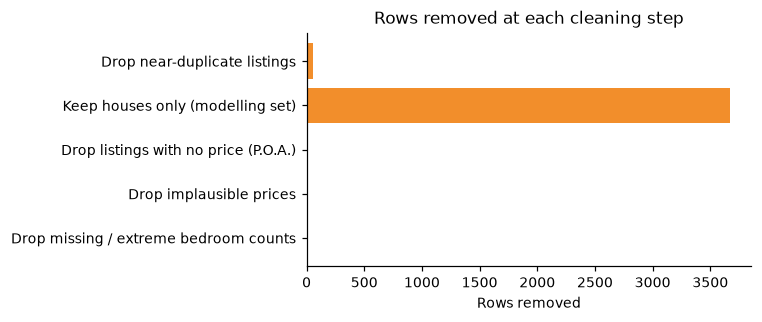

In [13]:
removed = log_table[log_table["rows_removed"].astype(float) > 0]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(removed["step"], removed["rows_removed"].astype(float), color="#F28E2B"); ax.invert_yaxis()
ax.set_xlabel("Rows removed"); ax.set_title("Rows removed at each cleaning step")
save_show("fig_01_cleaning_steps.png")

### Missing values before and after

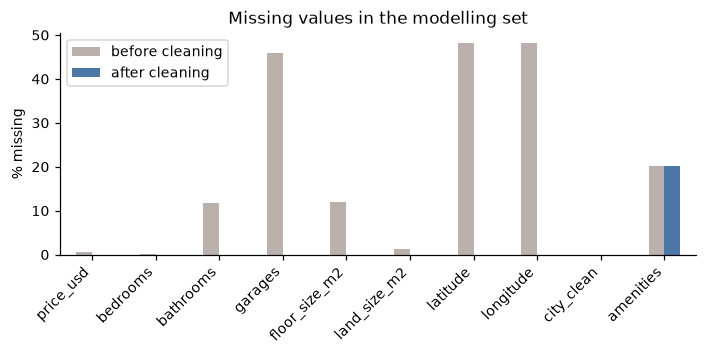

In [14]:
after = houses.reindex(columns=check_cols).isna().mean().mul(100)
mb = pd.DataFrame({"before cleaning": miss_before, "after cleaning": after.reindex(miss_before.index).fillna(0).round(1)})
mb.to_csv(os.path.join(TAB, "table_missing_before_after.csv"))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
mb.plot.bar(ax=ax, color=["#BAB0AC", "#4C78A8"]); ax.set_ylabel("% missing"); ax.set_title("Missing values in the modelling set")
plt.xticks(rotation=45, ha="right")
save_show("fig_02_missing_before_after.png")

## 11 · Explore the cleaned houses

From here on, `houses` is the cleaned modelling set. 

### Price distribution

2,283 houses | median $180,000 | mean $308,222 | 5th-95th percentile $35,000 to $950,000 | skewness 3.1 -> -0.0 after log


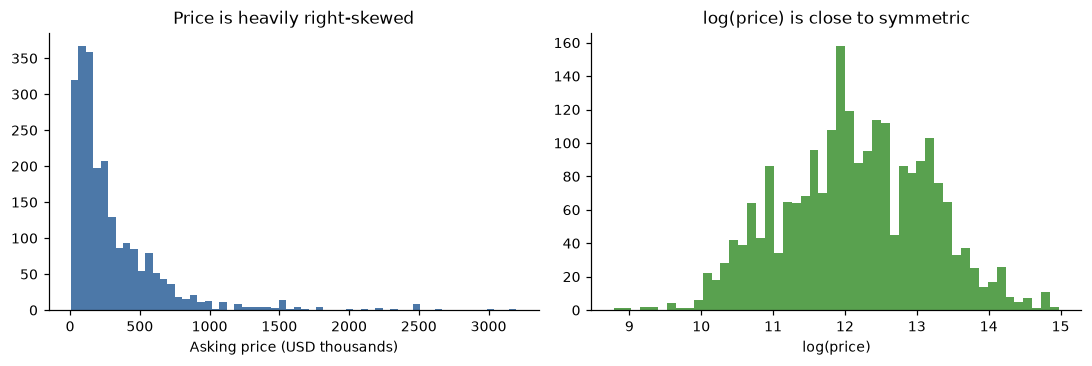

In [15]:
price = houses["price_usd"]
print(f"{len(houses):,} houses | median ${price.median():,.0f} | mean ${price.mean():,.0f} | 5th-95th percentile ${price.quantile(.05):,.0f} to ${price.quantile(.95):,.0f} | skewness {price.skew():.1f} -> {houses['log_price'].skew():.1f} after log")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(price / 1000, bins=60, color="#4C78A8"); ax[0].set_xlabel("Asking price (USD thousands)"); ax[0].set_title("Price is heavily right-skewed")
ax[1].hist(houses["log_price"], bins=50, color="#59A14F"); ax[1].set_xlabel("log(price)"); ax[1].set_title("log(price) is close to symmetric")
save_show("fig_03_price_distribution.png")

The mean is well above the median because a small number of expensive houses stretch the right tail. After taking logs the distribution is close to symmetric, which is the main reason to model `log_price` instead of raw price.

### Numeric summary

In [16]:
num = ["price_usd", "bedrooms", "bathrooms", "garages", "floor_size_m2", "land_size_m2", "n_amenities", "desc_words", "listing_age_days"]
summary_table = houses[num].describe(percentiles=[.05, .25, .5, .75, .95]).T.round(1)
summary_table.to_csv(os.path.join(TAB, "table_numeric_summary.csv"))
display(summary_table)

,count,mean,std,min,5%,25%,50%,75%,95%,max
price_usd,2283.0,308222.0,355424.8,6500.0,35000.0,95000.0,180000.0,400000.0,950000.0,3200000.0
bedrooms,2283.0,4.1,1.3,1.0,3.0,3.0,4.0,5.0,7.0,12.0
bathrooms,2283.0,2.6,1.4,1.0,1.0,2.0,2.0,3.0,6.0,12.0
garages,2283.0,0.8,0.9,0.0,0.0,0.0,1.0,1.0,2.0,8.0
floor_size_m2,2283.0,448.0,504.7,40.0,100.0,200.0,300.0,500.0,1200.0,4000.0
land_size_m2,2283.0,2817.6,5742.4,100.0,240.0,500.0,1600.0,3800.0,8189.5,100000.0
n_amenities,2283.0,8.5,7.2,0.0,0.0,2.0,8.0,13.5,22.0,40.0
desc_words,2283.0,124.1,71.4,1.0,26.0,69.0,119.0,166.5,241.0,584.0
listing_age_days,2283.0,145.6,205.4,0.0,5.0,30.5,76.0,174.0,495.8,2351.0


### Location: city and area

,n,median_price,mean_price,p25,p75
city_clean,,,,,
Harare,1626,230000.0,358872.0,115000.0,475000.0
Bulawayo,246,180000.0,221675.0,116250.0,252250.0
Other,345,120000.0,182768.0,70000.0,200000.0
Chitungwiza,66,37500.0,38750.0,31250.0,45000.0


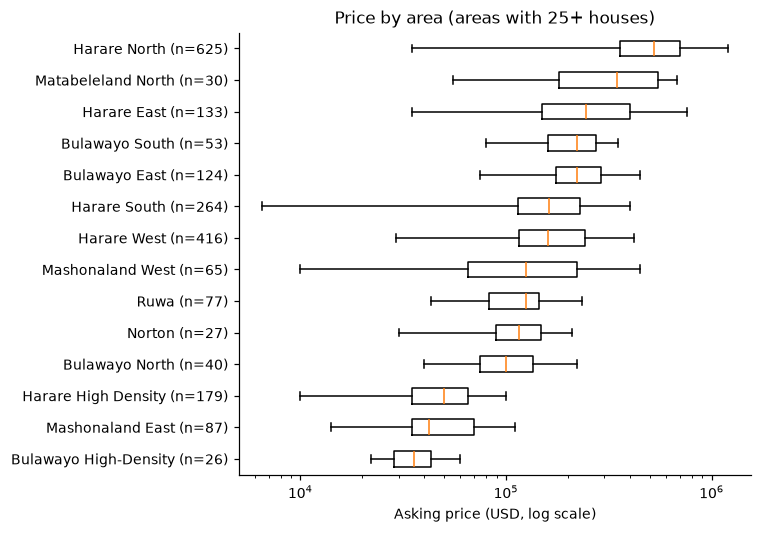

In [17]:
def price_table(col, min_n=1):
    t = houses.groupby(col).agg(n=("price_usd", "size"), median_price=("price_usd", "median"), mean_price=("price_usd", "mean"),
                                p25=("price_usd", lambda s: s.quantile(.25)), p75=("price_usd", lambda s: s.quantile(.75)))
    return t[t["n"] >= min_n].sort_values("median_price", ascending=False).round(0)

by_city = price_table("city_clean"); by_city.to_csv(os.path.join(TAB, "table_price_by_city.csv")); display(by_city)

areas = price_table("area_clean", 25).sort_values("median_price")
areas.to_csv(os.path.join(TAB, "table_price_by_area.csv"))
fig, ax = plt.subplots(figsize=(7, max(3, 0.28 * len(areas) + 1)))
boxes(ax, [houses.loc[houses["area_clean"] == a, "price_usd"] for a in areas.index], [f"{a} (n={int(n)})" for a, n in zip(areas.index, areas["n"])], horizontal=True)
ax.set_xscale("log"); ax.set_xlabel("Asking price (USD, log scale)"); ax.set_title("Price by area (areas with 25+ houses)")
save_show("fig_04_price_by_area.png")

Location is clearly one of the strongest drivers of price. Within Harare the spread between areas is very large (northern suburbs versus the high-density suburbs), and houses outside the big cities are cheaper still. This is why suburb and coordinates are kept as model features.

### Bedrooms and size

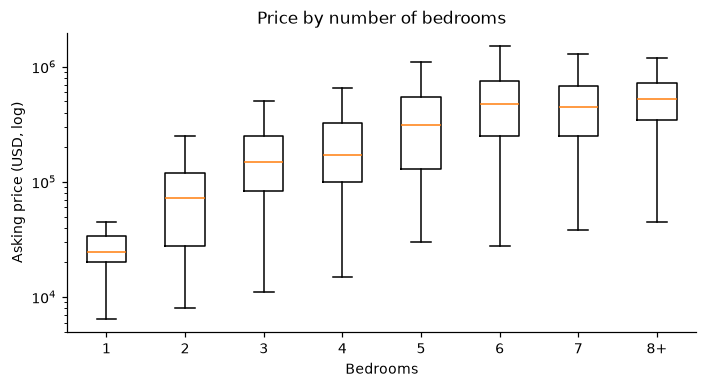

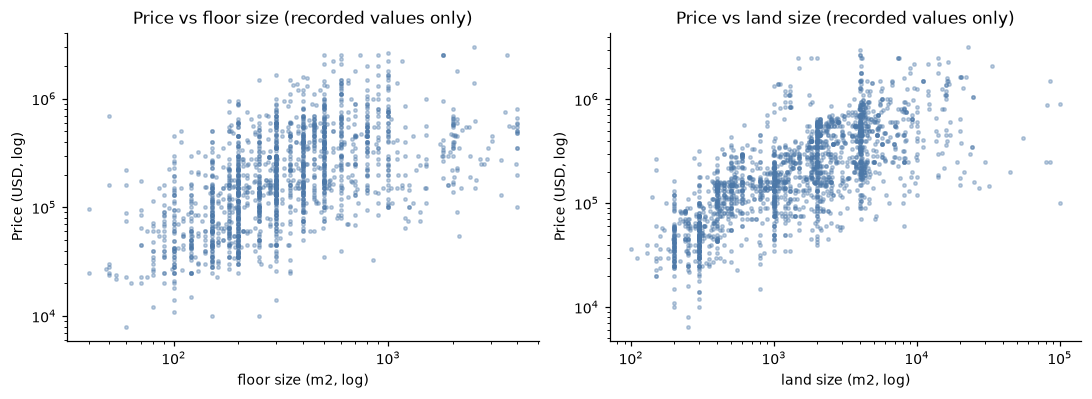

correlation of log price with log floor_size_m2 (recorded values): 0.57
correlation of log price with log land_size_m2 (recorded values): 0.74


In [18]:
bed = houses["bedrooms"].clip(upper=8).astype(int)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
boxes(ax, [houses.loc[bed == b, "price_usd"] for b in sorted(bed.unique())], [str(b) if b < 8 else "8+" for b in sorted(bed.unique())])
ax.set_yscale("log"); ax.set_xlabel("Bedrooms"); ax.set_ylabel("Asking price (USD, log)"); ax.set_title("Price by number of bedrooms")
save_show("fig_05_price_by_bedrooms.png")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.7))
for a, col, lab in zip(ax, ["floor_size_m2", "land_size_m2"], ["floor size", "land size"]):
    real = houses[col + "_imputed"] == 0
    a.scatter(houses.loc[real, col], houses.loc[real, "price_usd"], s=5, alpha=.35, color="#4C78A8")
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel(f"{lab} (m2, log)"); a.set_ylabel("Price (USD, log)"); a.set_title(f"Price vs {lab} (recorded values only)")
save_show("fig_06_price_vs_size.png")
for col in ("floor_size_m2", "land_size_m2"):
    real = houses[col + "_imputed"] == 0
    print(f"correlation of log price with log {col} (recorded values): {np.corrcoef(np.log(houses.loc[real, col]), houses.loc[real, 'log_price'])[0, 1]:.2f}")

Price rises with bedrooms up to about six, then becomes erratic because there are few very large houses (a handful of houses with 9 or more bedrooms). Both floor size and land size show a clear positive relationship with price on the log-log scale, with a lot of scatter, so size on its own will not be enough to predict price. The vertical stripes are rounding: agents tend to quote round sizes such as 300, 500 or 1,000 m².

### Amenities

,feature,n_with,share_%,median_with,median_without,median_ratio
21,amen_swimming_pool,388,17.0,520000.0,155000.0,3.35
26,amen_double_storey,280,12.3,550000.0,165000.0,3.33
22,amen_study_office,303,13.3,495000.0,165000.0,3.00
38,flag_pool,578,25.3,450000.0,150000.0,3.00
30,amen_intercom_system,130,5.7,500000.0,175000.0,2.86
20,amen_electric_gate,391,17.1,450000.0,160000.0,2.81
34,amen_split_level,80,3.5,490000.0,180000.0,2.72
31,amen_air_conditioning,120,5.3,475000.0,180000.0,2.64
15,amen_entertainment_area,458,20.1,397500.0,160000.0,2.48
36,flag_borehole,1289,56.5,280000.0,115000.0,2.43


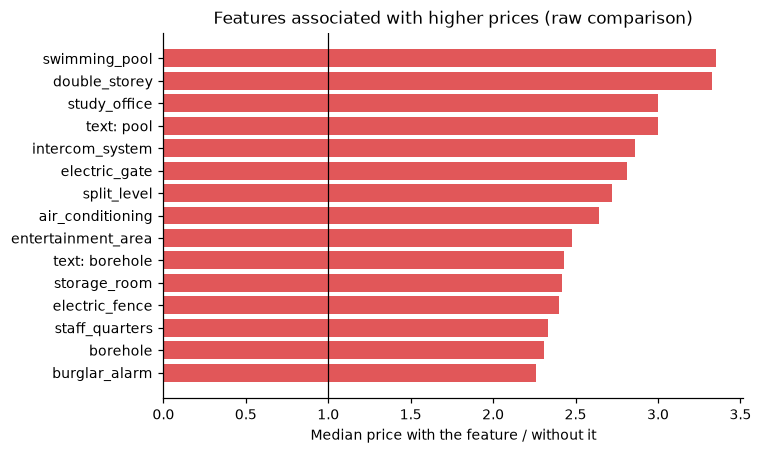

In [19]:
candidates = amen_cols + ["flag_borehole", "flag_solar", "flag_pool", "flag_cottage", "flag_title_deeds", "flag_cession"]
rows = []
for c in candidates:
    w, wo = houses.loc[houses[c] == 1, "price_usd"], houses.loc[houses[c] == 0, "price_usd"]
    if len(w) >= 30:
        rows.append({"feature": c, "n_with": len(w), "share_%": round(100 * len(w) / len(houses), 1),
                     "median_with": w.median(), "median_without": wo.median(), "median_ratio": round(w.median() / wo.median(), 2)})
premium = pd.DataFrame(rows).sort_values("median_ratio", ascending=False)
premium.to_csv(os.path.join(TAB, "table_feature_price_premium.csv"), index=False)
display(premium.head(10))

top = premium[premium["n_with"] >= 50].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top["feature"].str.replace("amen_", "").str.replace("flag_", "text: "), top["median_ratio"], color="#E15759"); ax.axvline(1, color="k", lw=.8)
ax.set_xlabel("Median price with the feature / without it"); ax.set_title("Features associated with higher prices (raw comparison)")
save_show("fig_07_feature_premium.png")

**Read this carefully.** These are raw comparisons, not effects. Houses with a pool, a study or an electric gate also tend to be bigger and in wealthier suburbs, so part of the gap reflects size and location, not the feature itself. The models in step 3 will separate these out.

### Correlations

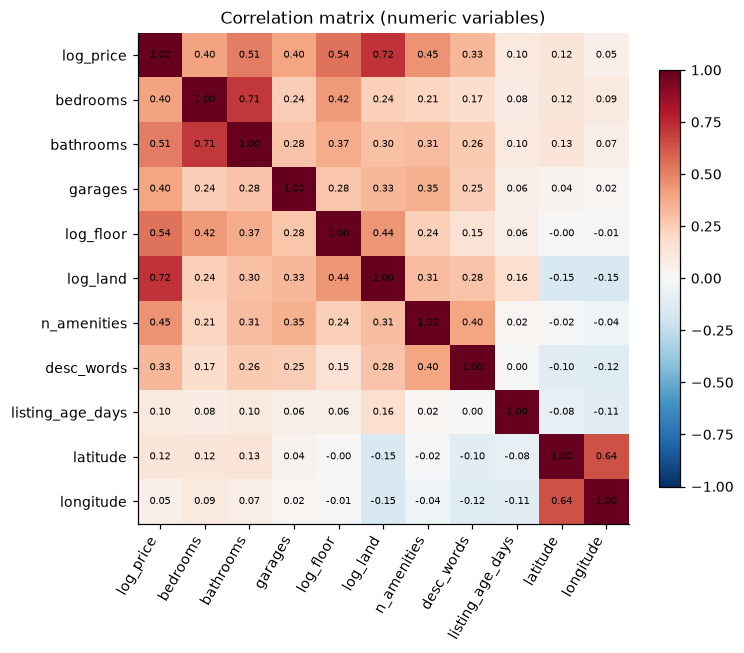

,log_land,log_floor,bathrooms,n_amenities,bedrooms,garages,desc_words,latitude,listing_age_days,longitude
correlation with log_price,0.72,0.54,0.51,0.45,0.4,0.4,0.33,0.12,0.1,0.05


In [20]:
cc = houses[["log_price", "bedrooms", "bathrooms", "garages", "floor_size_m2", "land_size_m2", "n_amenities", "desc_words", "listing_age_days", "latitude", "longitude"]].copy()
cc["floor_size_m2"], cc["land_size_m2"] = np.log(cc["floor_size_m2"]), np.log(cc["land_size_m2"])
cc = cc.rename(columns={"floor_size_m2": "log_floor", "land_size_m2": "log_land"})
corr = cc.corr()
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, shrink=.8); ax.set_title("Correlation matrix (numeric variables)")
save_show("fig_08_correlation.png")
display(corr["log_price"].drop("log_price").sort_values(ascending=False).round(2).to_frame("correlation with log_price").T)

Land size has the strongest linear relationship with log price (about 0.72), followed by floor size, bathrooms and the number of amenities. Latitude and longitude show only weak *linear* correlation (about 0.12 and 0.05), which does not mean location is unimportant. Location effects are not a straight line (price depends on which suburb, not on how far north), and about half the coordinates are suburb averages. That is why suburb and area are used as categories, and why the neural network will be given them in a form that can capture non-linear patterns.

### Where the houses are

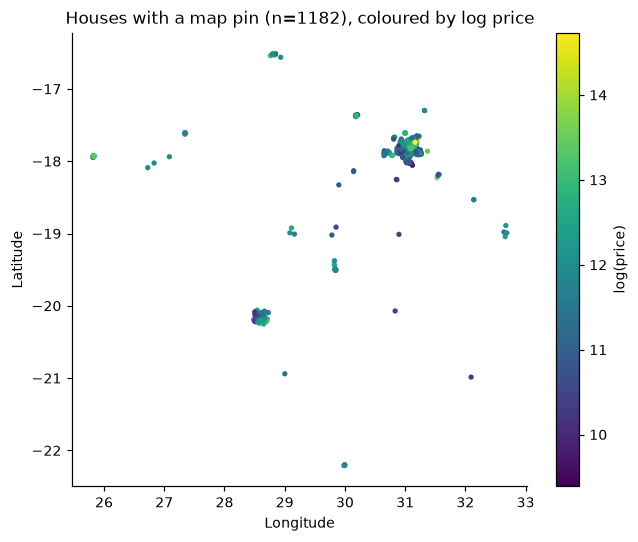

In [21]:
known = houses["latitude_imputed"] == 0
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(houses.loc[known, "longitude"], houses.loc[known, "latitude"], c=houses.loc[known, "log_price"], s=6, cmap="viridis")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title(f"Houses with a map pin (n={int(known.sum())}), coloured by log price")
fig.colorbar(sc, label="log(price)")
save_show("fig_09_map.png")

## 12 · Summary and what comes next

**The cleaned dataset.** The modelling set `data/houses_clean.csv` holds the houses that survived cleaning, with the target `price_usd` / `log_price` and the predictors: location (city, area, suburb, coordinates), size and room counts, amenities (0/1 columns), text-derived flags, and the full `description` for the text model. The photos are linked to rows by `listing_id`.

**Findings so far.**
* Asking prices are strongly right-skewed, which supports modelling the log of price.
* Location, size and bedrooms all show a clear relationship with price; amenities such as a pool or study go with higher prices, though part of that is confounding with size and location.

**Limitations to carry into the report.**
* These are *asking* prices, not sale prices.
* Coordinates are missing for about half the houses (filled from the suburb average), and garages are only counted when mentioned in the advert.
* Some floor and land sizes were impossible and replaced by estimates; the `_imputed` columns mark them.
* The listings are a snapshot taken on the collection dates, and a few adverts are older than a year.

**Next:** `03_models.ipynb` fits the log-price linear regression baseline and the multimodal network (tabular features + photos with a CNN + descriptions as text embeddings), then evaluates both on held-out data.